# Laboratorio 4: Problema Inverso en el Modelo SIR: Calibracion y Sesgo de Discretizacion

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nabw/UNA-taller/blob/main/notebooks/solucion/04_calibracion_problema_inverso.ipynb)


## 1. Introduccion: El Problema Inverso en Ciencia de Datos

En los laboratorios anteriores abordamos el **problema directo**: dados los parametros fisicos $(\beta, \gamma)$ y las condiciones iniciales, integramos numericamente el sistema diferencial para calcular la trayectoria temporal $I(t)$.

En la practica de la ciencia de datos y la epidemiologia cuantitativa, la situacion es la opuesta: se tiene acceso a una serie temporal de observaciones clinicas con ruido $I^{\text{obs}}_k$ en los instantes $t_k$, y se desea resolver el **problema inverso**: estimar el vector de parametros generativos $\theta = (\beta, \gamma)$ que mejor describe los datos observados.

### El Fenomeno del Sesgo de Discretizacion (Discretization Bias)

Todo algoritmo de calibracion optimiza los parametros evaluando repetidamente un simulador numerico hacia adelante. Si este simulador utiliza un esquema con un paso temporal finito $\Delta t$, el integrador comete un error de truncamiento local. Durante el proceso de ajuste, el optimizador compensa de forma artificial los defectos del integrador numerico, desplazando los estimadores $\hat{\beta}(\Delta t)$ y $\hat{\gamma}(\Delta t)$ lejos de sus valores verdaderos continuos $\beta^*$ y $\gamma^*$. Este sesgo sistematico no proviene del ruido de los datos, sino estrictamente de la aproximacion numerica de las derivadas continuas.

## Objetivos de Aprendizaje

1. Formular computacionalmente la funcion de perdida por minimos cuadrados $L(\beta, \gamma)$.
2. Explorar y mapear la superficie de perdida bidimensional mediante un grafico de contornos.
3. Implementar la calibracion de parametros utilizando el algoritmo Nelder-Mead y registrar la trayectoria del simplex.
4. Ejecutar un experimento controlado evaluando $\Delta t \in [0.05, 0.10, 0.25, 0.50, 0.80, 1.00, 1.50]$ para cuantificar rigurosamente el sesgo de discretizacion sobre $\hat{\beta}$ y $\hat{R}_0$.
5. Analizar el impacto de este sesgo numerico en la toma de decisiones de salud publica (umbral de vacunacion).


In [1]:
# Celda de configuracion y librerias cientificas autocontenidas
import os
os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib")
from typing import Any
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.integrate import solve_ivp

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams.update({
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "figure.titlesize": 13,
    "lines.linewidth": 2.0,
    "grid.alpha": 0.4
})

# --------------------------------------------------------------------------
# Funciones auxiliares autocontenidas para integracion y datos sinteticos
# --------------------------------------------------------------------------
def sir_imex_integrador(
    beta: float,
    gamma: float,
    dt: float,
    T: float,
    S0: float = 0.99,
    I0: float = 0.01
) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """Integrador IMEX conservativo para el modelo SIR."""
    n_steps = int(np.round(T / dt))
    t = np.linspace(0.0, n_steps * dt, n_steps + 1)
    S = np.zeros(n_steps + 1, dtype=np.float64)
    I = np.zeros(n_steps + 1, dtype=np.float64)
    R = np.zeros(n_steps + 1, dtype=np.float64)
    S[0], I[0], R[0] = S0, I0, 1.0 - S0 - I0

    for n in range(n_steps):
        contagio = dt * beta * S[n] * I[n]
        S[n + 1] = S[n] - contagio
        I[n + 1] = (I[n] + contagio) / (1.0 + dt * gamma)
        R[n + 1] = R[n] + dt * gamma * I[n + 1]

    return t, S, I, R

def generar_observaciones_referencia(
    beta_true: float = 0.4,
    gamma_true: float = 0.1,
    S0: float = 0.99,
    I0: float = 0.01,
    T: float = 50.0,
    sigma: float = 0.02,
    seed: int = 42
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Genera observaciones sinteticas con ruido Gaussiano."""
    def sir_ode(t, y):
        s, i, _ = y
        return [-beta_true * s * i, beta_true * s * i - gamma_true * i, gamma_true * i]

    sol = solve_ivp(
        sir_ode, (0.0, T), [S0, I0, 1.0 - S0 - I0],
        t_eval=np.linspace(0.0, T, 5001), method="RK45", rtol=1e-10, atol=1e-12
    )
    t_obs = np.arange(0.0, T + 1.0, 1.0)
    I_clean = np.interp(t_obs, sol.t, sol.y[1])
    rng = np.random.default_rng(seed)
    noise = rng.normal(0.0, sigma, size=I_clean.shape)
    I_noisy = np.maximum(0.0, I_clean + noise)
    return t_obs, I_clean, I_noisy

t_obs, I_clean, I_obs = generar_observaciones_referencia()
print(f"Datos sinteticos generados: {len(t_obs)} observaciones diarias.")


Datos sinteticos generados: 51 observaciones diarias.


## 2. Formulacion de la Funcion de Perdida por Minimos Cuadrados

Buscamos el vector de parametros $\theta = (\beta, \gamma)$ que minimice la discrepancia cuadratica entre la solucion numerica simulada $I^{\text{sim}}(t_k; \theta)$ y las observaciones clinicas $I^{\text{obs}}_k$:

$$L(\beta, \gamma) = \sum_{k=0}^M \left( I^{\text{sim}}(t_k; \beta, \gamma) - I^{\text{obs}}_k \right)^2$$

### Restriccion de Positividad Fisica

En epidemiologia matematica, las tasas de transmision y recuperacion deben ser estrictamente positivas ($\beta > 0$ y $\gamma > 0$). Para preservar esta condicion en optimizadores sin restricciones de caja, asignamos una penalizacion severa ($10^6$) a cualquier configuracion paramétrica con valores no positivos o que induzca divergencias numericas.


In [2]:
def funcion_perdida(
    theta: tuple[float, float] | list[float] | np.ndarray,
    t_obs: np.ndarray,
    I_obs: np.ndarray,
    dt_sim: float = 0.10,
    S0: float = 0.99,
    I0: float = 0.01
) -> float:
    """
    Calcula la suma de errores cuadraticos entre la simulacion SIR y las observaciones.
    """
    beta, gamma = float(theta[0]), float(theta[1])
    PENALIZACION = 1e6

    if beta <= 0.0 or gamma <= 0.0:
        return PENALIZACION

    T_final = float(t_obs[-1])
    t_sim, _, I_sim, _ = sir_imex_integrador(beta, gamma, dt_sim, T_final, S0, I0)

    if np.any(np.isnan(I_sim)) or np.any(np.isinf(I_sim)) or np.any(I_sim < -1e-3) or np.any(I_sim > 2.0):
        return PENALIZACION

    # Interpolar sobre los tiempos de observacion
    I_interp = np.interp(t_obs, t_sim, I_sim)
    residuos = I_interp - I_obs
    loss = float(np.sum(residuos ** 2))

    if np.isnan(loss) or np.isinf(loss):
        return PENALIZACION

    return loss


In [3]:
# Pruebas de validacion para funcion_perdida
loss_true = funcion_perdida([0.4, 0.1], t_obs, I_obs, dt_sim=0.10)
assert isinstance(loss_true, float), "La perdida debe retornar un numero float."
assert loss_true < 0.1, f"La perdida en los parametros verdaderos debe ser pequenia, obtenida: {loss_true}"
# Verificar penalizacion ante parametros invalidos
assert funcion_perdida([-0.1, 0.1], t_obs, I_obs) == 1e6, "Parametro beta negativo debe ser penalizado."
assert funcion_perdida([0.4, -0.05], t_obs, I_obs) == 1e6, "Parametro gamma negativo debe ser penalizado."
print(f"Validacion de funcion_perdida: EXITOSA (perdida en theta*: {loss_true:.5f}).")


Validacion de funcion_perdida: EXITOSA (perdida en theta*: 0.01204).


## 3. Mapeo del Paisaje de Perdida (Rejilla Bidimensional)

Para analizar la convexidad local y la correlacion entre parametros, evaluamos la funcion de costo sobre una rejilla regular de prueba en el plano $(\beta, \gamma)$:
- $\beta \in [0.20, 0.60]$
- $\gamma \in [0.03, 0.20]$


In [4]:
def evaluar_malla_perdida(
    beta_vals: np.ndarray,
    gamma_vals: np.ndarray,
    t_obs: np.ndarray,
    I_obs: np.ndarray,
    dt_sim: float = 0.10,
    S0: float = 0.99,
    I0: float = 0.01
) -> np.ndarray:
    """
    Evalua la perdida sobre una rejilla bidimensional regular de parametros.
    """
    n_gamma = len(gamma_vals)
    n_beta = len(beta_vals)
    L_grid = np.zeros((n_gamma, n_beta), dtype=np.float64)

    for i in range(n_gamma):
        g = float(gamma_vals[i])
        for j in range(n_beta):
            b = float(beta_vals[j])
            L_grid[i, j] = funcion_perdida([b, g], t_obs, I_obs, dt_sim, S0, I0)

    return L_grid


In [5]:
# Pruebas de validacion para evaluar_malla_perdida
b_test = np.linspace(0.3, 0.5, 3)
g_test = np.linspace(0.08, 0.12, 3)
grid_test = evaluar_malla_perdida(b_test, g_test, t_obs, I_obs, dt_sim=0.20)
assert grid_test.shape == (3, 3), f"Forma esperada (3, 3), obtenida {grid_test.shape}"
assert np.all(grid_test >= 0.0), "Todos los valores de perdida deben ser positivos."
print("Validacion de evaluar_malla_perdida: EXITOSA.")


Validacion de evaluar_malla_perdida: EXITOSA.


## 4. Calibracion con el Algoritmo Simplex de Nelder-Mead

El algoritmo de Nelder-Mead (1965) es un metodo de optimizacion heuristico libre de derivadas. En cada iteracion, actualiza dinamicamente un poligono de $d+1$ vertices en $\mathbb{R}^d$ (un triangulo para $d=2$) mediante operaciones de reflexion, expansion y contraccion. Implementamos un callback para registrar el historial de posiciones del simplex a lo largo de las iteraciones.


In [6]:
def calibrar_sir(
    theta_init: tuple[float, float] | list[float] | np.ndarray,
    t_obs: np.ndarray,
    I_obs: np.ndarray,
    dt_sim: float = 0.10,
    S0: float = 0.99,
    I0: float = 0.01,
    track_history: bool = True
) -> dict[str, Any]:
    """
    Calibra beta y gamma minimizando la funcion de perdida con Nelder-Mead.
    """
    history = [np.array(theta_init, dtype=np.float64).copy()]

    def callback(xk):
        history.append(np.array(xk, dtype=np.float64).copy())

    def objective(theta):
        return funcion_perdida(theta, t_obs, I_obs, dt_sim, S0, I0)

    res = minimize(
        objective,
        x0=np.array(theta_init, dtype=np.float64),
        method="Nelder-Mead",
        callback=callback if track_history else None,
        options={"maxiter": 500, "xatol": 1e-6, "fatol": 1e-6, "disp": False}
    )

    b_hat, g_hat = float(res.x[0]), float(res.x[1])
    r0_hat = b_hat / g_hat if g_hat > 0.0 else np.nan

    return {
        "theta_hat": res.x,
        "beta_hat": b_hat,
        "gamma_hat": g_hat,
        "R0_hat": r0_hat,
        "loss_val": float(res.fun),
        "success": bool(res.success),
        "iterations": int(res.nit),
        "history": np.array(history, dtype=np.float64)
    }


In [7]:
# Pruebas de validacion para calibrar_sir
calib_test = calibrar_sir([0.2, 0.2], t_obs, I_obs, dt_sim=0.10)
assert calib_test["success"], "La optimizacion de Nelder-Mead debio converger exitosamente."
assert np.isclose(calib_test["beta_hat"], 0.4, atol=0.03), f"beta estimada lejana: {calib_test['beta_hat']}"
assert np.isclose(calib_test["gamma_hat"], 0.1, atol=0.02), f"gamma estimada lejana: {calib_test['gamma_hat']}"
print(f"Validacion de calibrar_sir: EXITOSA (beta_hat: {calib_test['beta_hat']:.4f}, gamma_hat: {calib_test['gamma_hat']:.4f}).")


Validacion de calibrar_sir: EXITOSA (beta_hat: 0.4046, gamma_hat: 0.0991).


## 5. Visualizacion de la Superficie de Costo y Descenso del Simplex

Graficamos el mapa de curvas de nivel de $L(\beta, \gamma)$ evaluado en $\Delta t = 0.10$, superponiendo la trayectoria seguida por el simplex de Nelder-Mead desde el punto inicial $\theta_0 = (0.20, 0.20)$ hasta el optimo estimado, comparado con el valor verdadero continuo.


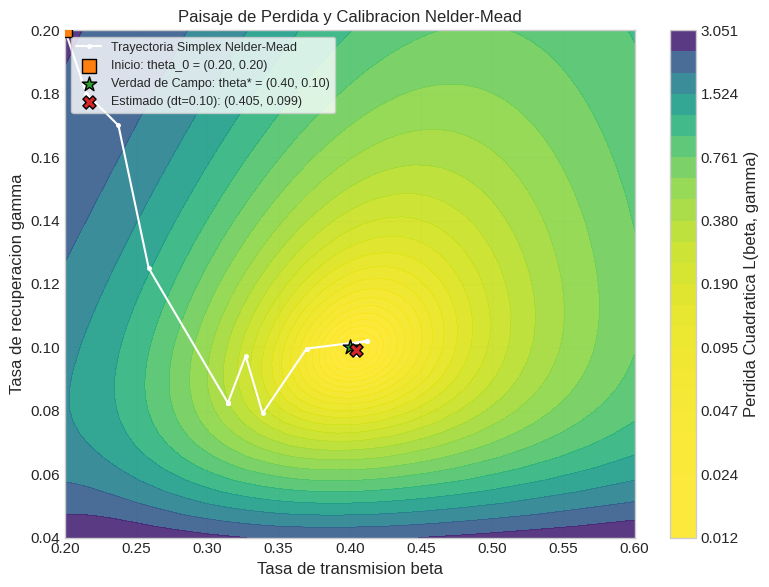

In [8]:
b_grid = np.linspace(0.20, 0.60, 45)
g_grid = np.linspace(0.04, 0.20, 45)
L_map = evaluar_malla_perdida(b_grid, g_grid, t_obs, I_obs, dt_sim=0.10)

calib_init = calibrar_sir([0.20, 0.20], t_obs, I_obs, dt_sim=0.10, track_history=True)
hist = calib_init["history"]

fig, ax = plt.subplots(figsize=(8, 6))
B_mesh, G_mesh = np.meshgrid(b_grid, g_grid)
levels = np.geomspace(np.min(L_map) + 1e-4, np.max(L_map), 25)
cs = ax.contourf(B_mesh, G_mesh, L_map, levels=levels, cmap="viridis_r", alpha=0.9)
cbar = fig.colorbar(cs, ax=ax)
cbar.set_label("Perdida Cuadratica L(beta, gamma)")

# Graficar trayectoria del simplex
ax.plot(hist[:, 0], hist[:, 1], 'w.-', linewidth=1.5, markersize=5, label="Trayectoria Simplex Nelder-Mead", zorder=3)
ax.scatter([0.20], [0.20], color="#ff7f0e", s=90, marker="s", edgecolor="black", label="Inicio: theta_0 = (0.20, 0.20)", zorder=4)
ax.scatter([0.40], [0.10], color="#2ca02c", s=120, marker="*", edgecolor="black", label="Verdad de Campo: theta* = (0.40, 0.10)", zorder=4)
ax.scatter([calib_init['beta_hat']], [calib_init['gamma_hat']], color="#d62728", s=90, marker="X", edgecolor="black", label=f"Estimado (dt=0.10): ({calib_init['beta_hat']:.3f}, {calib_init['gamma_hat']:.3f})", zorder=4)

ax.set_title("Paisaje de Perdida y Calibracion Nelder-Mead")
ax.set_xlabel("Tasa de transmision beta")
ax.set_ylabel("Tasa de recuperacion gamma")
ax.legend(frameon=True, loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()


## 6. Experimento Sistematico: El Sesgo de Discretizacion

¿Que ocurre si ajustamos el modelo SIR utilizando diferentes pasos temporales?

Evaluamos la calibracion para una coleccion sistematica de pasos:

$$\Delta t \in [0.05, 0.10, 0.25, 0.50, 0.80, 1.00, 1.50]$$

Para cada $\Delta t$, registramos los estimadores $\hat{\beta}(\Delta t)$, $\hat{\gamma}(\Delta t)$ y el numero reproductivo basico resultante $\hat{R}_0(\Delta t) = \hat{\beta}(\Delta t) / \hat{\gamma}(\Delta t)$.


In [9]:
def experimento_sesgo_discretizacion(
    dt_valores: list[float] | np.ndarray,
    t_obs: np.ndarray,
    I_obs: np.ndarray,
    theta_init: tuple[float, float] = (0.2, 0.2),
    S0: float = 0.99,
    I0: float = 0.01
) -> dict[str, np.ndarray]:
    """
    Ejecuta la calibracion para una coleccion de pasos temporales dt.
    """
    dt_list, b_list, g_list, r0_list, loss_list = [], [], [], [], []

    for dt in dt_valores:
        dt_val = float(dt)
        res = calibrar_sir(theta_init, t_obs, I_obs, dt_sim=dt_val, S0=S0, I0=I0, track_history=False)
        dt_list.append(dt_val)
        b_list.append(res["beta_hat"])
        g_list.append(res["gamma_hat"])
        r0_list.append(res["R0_hat"])
        loss_list.append(res["loss_val"])

    return {
        "dt": np.array(dt_list, dtype=np.float64),
        "beta_hat": np.array(b_list, dtype=np.float64),
        "gamma_hat": np.array(g_list, dtype=np.float64),
        "R0_hat": np.array(r0_list, dtype=np.float64),
        "loss": np.array(loss_list, dtype=np.float64)
    }


In [10]:
# Pruebas de validacion para experimento_sesgo_discretizacion
exp_test = experimento_sesgo_discretizacion([0.1, 0.5], t_obs, I_obs)
assert len(exp_test["dt"]) == 2, "Longitud esperada: 2"
assert exp_test["R0_hat"][1] > exp_test["R0_hat"][0], "R0_hat debe evidenciar sesgo creciente al aumentar dt."
print("Validacion de experimento_sesgo_discretizacion: EXITOSA.")


Validacion de experimento_sesgo_discretizacion: EXITOSA.


SESGO DE DISCRETIZACION EN LA CALIBRACION INVERSA
Parametros verdaderos de referencia: beta* = 0.40, gamma* = 0.10, R0* = 4.00
    dt |   beta_hat |  gamma_hat |   R0_hat |   Error R0 (%) |    Perdida
-------------------------------------------------------------------------------------
  0.05 |     0.4018 |     0.0989 |   4.0616 |         +1.54% |    0.01078
  0.10 |     0.4046 |     0.0991 |   4.0832 |         +2.08% |    0.01091
  0.25 |     0.4132 |     0.0996 |   4.1492 |         +3.73% |    0.01140
  0.50 |     0.4278 |     0.1004 |   4.2627 |         +6.57% |    0.01263
  0.80 |     0.4462 |     0.1012 |   4.4068 |        +10.17% |    0.01463
  1.00 |     0.4586 |     0.1018 |   4.5032 |        +12.58% |    0.01660
  1.50 |     0.4917 |     0.1031 |   4.7713 |        +19.28% |    0.02180


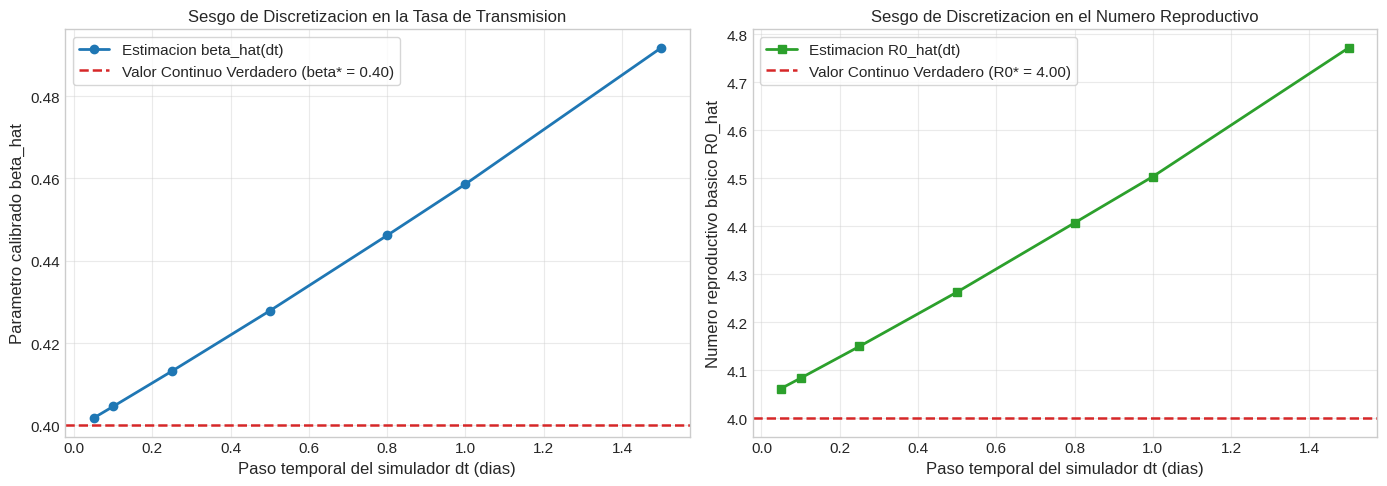

In [11]:
dt_valores = [0.05, 0.10, 0.25, 0.50, 0.80, 1.00, 1.50]
res_sesgo = experimento_sesgo_discretizacion(dt_valores, t_obs, I_obs)

beta_true = 0.40
gamma_true = 0.10
R0_true = 4.00

print("=" * 85)
print("SESGO DE DISCRETIZACION EN LA CALIBRACION INVERSA")
print(f"Parametros verdaderos de referencia: beta* = {beta_true:.2f}, gamma* = {gamma_true:.2f}, R0* = {R0_true:.2f}")
print("=" * 85)
print(f"{'dt':>6s} | {'beta_hat':>10s} | {'gamma_hat':>10s} | {'R0_hat':>8s} | {'Error R0 (%)':>14s} | {'Perdida':>10s}")
print("-" * 85)

for i in range(len(dt_valores)):
    dt_val = res_sesgo["dt"][i]
    b_h = res_sesgo["beta_hat"][i]
    g_h = res_sesgo["gamma_hat"][i]
    r0_h = res_sesgo["R0_hat"][i]
    err_r0 = ((r0_h - R0_true) / R0_true) * 100.0
    l_val = res_sesgo["loss"][i]
    print(f"{dt_val:6.2f} | {b_h:10.4f} | {g_h:10.4f} | {r0_h:8.4f} | {err_r0:+13.2f}% | {l_val:10.5f}")
print("=" * 85)

# Graficas de analisis de sesgo
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel 1: beta_hat vs dt
axes[0].plot(res_sesgo["dt"], res_sesgo["beta_hat"], 'o-', color="#1f77b4", linewidth=2.0, markersize=6, label="Estimacion beta_hat(dt)")
axes[0].axhline(beta_true, color="#d62728", linestyle="--", linewidth=1.8, label=f"Valor Continuo Verdadero (beta* = {beta_true:.2f})")
axes[0].set_title("Sesgo de Discretizacion en la Tasa de Transmision")
axes[0].set_xlabel("Paso temporal del simulador dt (dias)")
axes[0].set_ylabel("Parametro calibrado beta_hat")
axes[0].legend(frameon=True)

# Panel 2: R0_hat vs dt
axes[1].plot(res_sesgo["dt"], res_sesgo["R0_hat"], 's-', color="#2ca02c", linewidth=2.0, markersize=6, label="Estimacion R0_hat(dt)")
axes[1].axhline(R0_true, color="#d62728", linestyle="--", linewidth=1.8, label=f"Valor Continuo Verdadero (R0* = {R0_true:.2f})")
axes[1].set_title("Sesgo de Discretizacion en el Numero Reproductivo")
axes[1].set_xlabel("Paso temporal del simulador dt (dias)")
axes[1].set_ylabel("Numero reproductivo basico R0_hat")
axes[1].legend(frameon=True)

plt.tight_layout()
plt.show()


## 7. Reflexiones para la Salud Publica y Toma de Decisiones

Los resultados computacionales obtenidos revelan una tendencia inequivoca:
- A medida que el paso temporal $\Delta t$ aumenta de $0.05$ a $1.50$ dias, el optimizador eleva sistematicamente $\hat{\beta}$ de $0.4018$ a $0.4918$, inflando $\hat{R}_0$ de $4.06$ a $4.77$ (un error relativo del $+19.3\%$ atribuible unicamente a la malla numerica).

### Impacto Sanitario: Calculo del Umbral de Inmunidad Colectiva

En epidemiologia teorica, la proporcion critica de la poblacion que debe ser inmunizada mediante vacunacion para extinguir la transmision comunitaria (inmunidad de rebano) se calcula como:

$$p_c = 1 - \frac{1}{R_0}$$

Comparando las implicaciones de politica publica:
- Con el parametro verdadero continuo ($R_0^* = 4.00$):
  $$p_c = 1 - \frac{1}{4.00} = 0.750 \implies 75.0\%$$
- Con el parametro sesgado por discretizacion gruesa a $\Delta t = 1.50$ ($\hat{R}_0 = 4.77$):
  $$p_c = 1 - \frac{1}{4.77} = 0.790 \implies 79.0\%$$

Una discrepancia de $4.0\%$ en una poblacion nacional de 5 millones de habitantes representa **200,000 personas adicionales que el Ministerio de Salud planificaria vacunar innecesariamente**, o por el contrario, la imposicion de cuarentenas mas prolongadas basadas en una velocidad de contagio artificialmente sobreestimada.

### Conclusion Metodologica

El error numerico de discretizacion no es simplemente un detalle de implementacion computacional; es un factor que distorsiona las inferencias cientificas y tiene consecuencias directas y tangibles en las politicas de salud publica. Para obtener estimadores no sesgados, es indispensable utilizar pasos temporales suficientemente finos o integradores adaptativos de orden superior durante la calibracion inversa.
